In [17]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np

In [18]:
data = pd.read_csv('cifar-10.csv')

In [19]:
data.head()

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071,label
0,59,43,50,68,98,119,139,145,149,149,...,58,65,59,46,57,104,140,84,72,6
1,154,126,105,102,125,155,172,180,142,111,...,42,67,101,122,133,136,139,142,144,9
2,255,253,253,253,253,253,253,253,253,253,...,83,80,69,66,72,79,83,83,84,9
3,28,37,38,42,44,40,40,24,32,43,...,39,59,42,44,48,38,28,37,46,4
4,170,168,177,183,181,177,181,184,189,189,...,88,85,82,83,79,78,82,78,80,1


In [20]:
x = data.drop('label',axis=1).values
y = data['label'].values

In [21]:
x = x / 255.0
x = x.reshape(-1,3072)

In [22]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [46]:
model = keras.Sequential([
    layers.Input(shape=(3072,)),
    layers.Dense(128,activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(64,activation = 'relu'),
    layers.Dense(10,activation= 'softmax')
])

In [47]:
model.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [48]:
history = model.fit(
    x_train,y_train,
    epochs = 10,
    batch_size = 32,
    validation_split = 0.2
)

Epoch 1/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.2258 - loss: 2.0673 - val_accuracy: 0.3045 - val_loss: 1.9013
Epoch 2/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.2717 - loss: 1.9627 - val_accuracy: 0.3256 - val_loss: 1.8692
Epoch 3/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.2926 - loss: 1.9173 - val_accuracy: 0.3223 - val_loss: 1.8445
Epoch 4/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.2993 - loss: 1.8918 - val_accuracy: 0.3486 - val_loss: 1.8215
Epoch 5/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.3063 - loss: 1.8795 - val_accuracy: 0.3521 - val_loss: 1.8252
Epoch 6/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.3107 - loss: 1.8622 - val_accuracy: 0.3475 - val_loss: 1.8323
Epoch 7/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.3216 - loss: 1.8499 - val_accuracy: 0.3581 - val_loss: 1.7978
Epoch 8/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.3251 - loss: 1.8436 - 

In [49]:
loss, accuracy = model.evaluate(x_test,y_test)
print("Training accuracry = ", history.history['accuracy'][-1] * 100)
print("Testing accuracy =" , accuracy *100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 344us/step - accuracy: 0.3739 - loss: 1.7648
Training accuracry =  33.15937519073486
Testing accuracy = 37.38999962806702


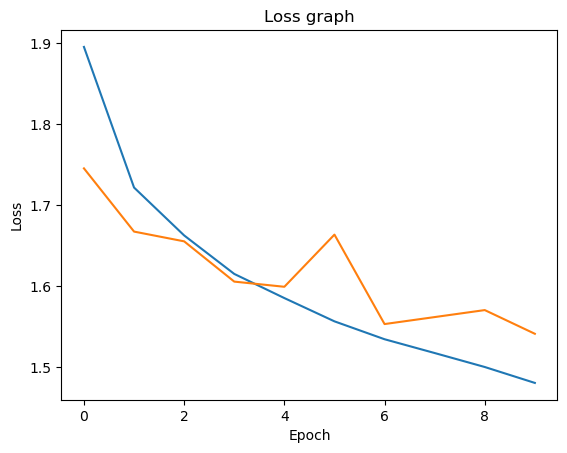

In [27]:
plt.plot(history.history['loss'],label='training loss')
plt.plot(history.history['val_loss'],label="testing loss")

plt.title('Loss graph')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.show()

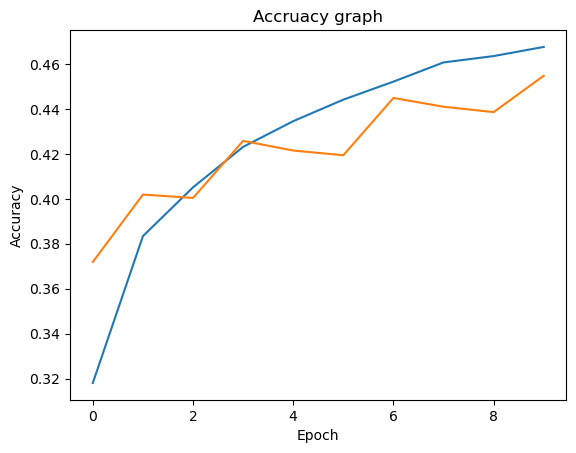

In [28]:
plt.plot(history.history['accuracy'],label = "training accuracy")
plt.plot(history.history['val_accuracy'],label = "testing accuracy")

plt.title("Accruacy graph")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()

In [29]:
predictions = model.predict(x_test)
prediction_labels = np.argmax(predictions,axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 300us/step


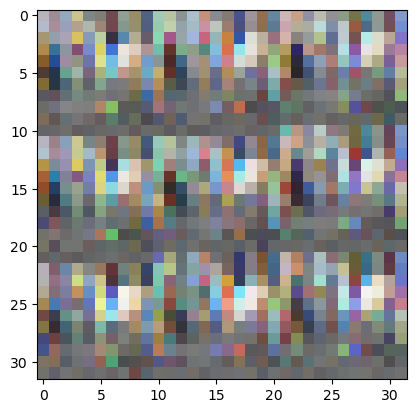

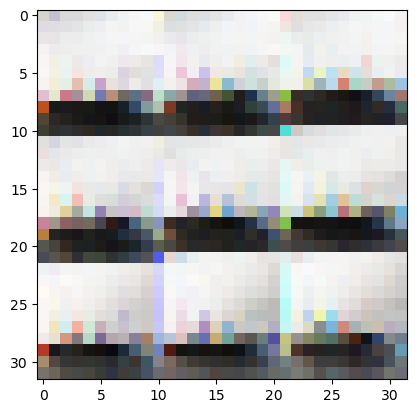

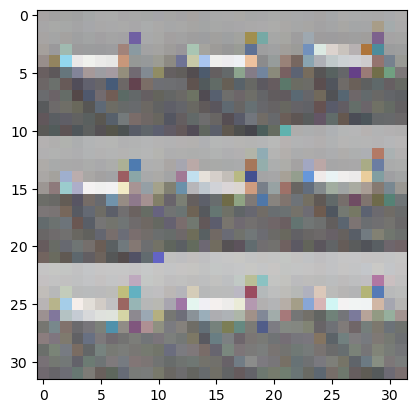

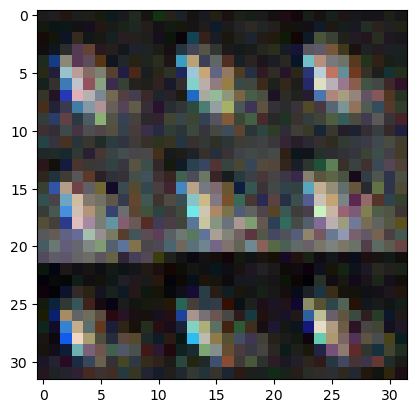

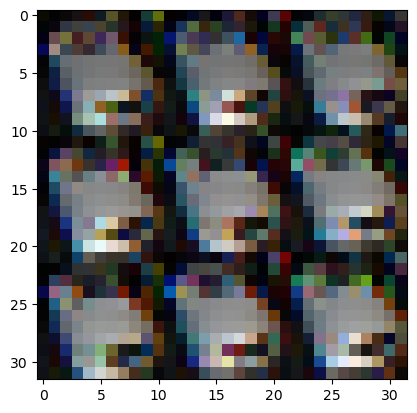

In [31]:
for i in range(5):
    plt.imshow(x_test[i].reshape(32,32,3))
    plt.show()
            

In [33]:
for i in range(5):
    print('Actual = ',y_test[i],
          'predicted = ',prediction_labels[i])

Actual =  7 predicted =  5
Actual =  8 predicted =  8
Actual =  0 predicted =  8
Actual =  6 predicted =  4
Actual =  1 predicted =  3
